<a href="https://colab.research.google.com/github/ArifahZhafirah/PCVK26_04_Arifah/blob/main/P7_Week7_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7 – Segmentasi Citra dengan Thresholding

#Tugas Individu (Langkah 1–7)

In [1]:
# Identitas
nama  = "Arifah Zhafirah Wikananda"
nim   = "244107020188"
kelas = "2C"
print(f"Nama  : {nama}")
print(f"NIM   : {nim}")
print(f"Kelas : {kelas}")

Nama  : Arifah Zhafirah Wikananda
NIM   : 244107020188
Kelas : 2C


## Langkah 1 – Mount Google Drive
Buka https://colab.research.google.com/. Setelah dipastikan bahwa google Colab
terhubung dengan Github Anda, lanjutkan dengan memilih repository yang telah
digunakan pada praktikum minggu lalu, rename file menjadi “Week7.ipynb”.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Langkah 2
Import beberapa library berikut yang akan digunakan selama uji coba praktikum
minggu ke-7 berikut.



In [3]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

## Langkah 3
Buat Global Threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV), dengan
threshold= 200, secara manual sehingga menghasilkan tampilan seperti berikut:

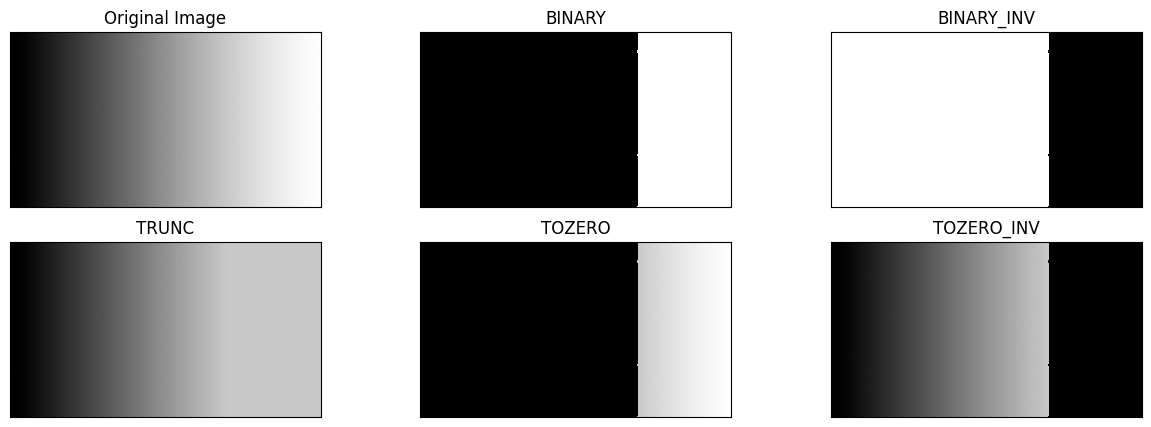

In [4]:
filename = ('/content/drive/MyDrive/Semester5/PCVK/P7_Arifah_04/gradient.jpg')
img = cv.imread(filename)
thresh = 200      #nilai Threshold yang ditentukan
maxval = 255

#1. BINARY: pixel>thresh -> maxval; selain itu 0
thresh1 = np.where(img > thresh, maxval, 0).astype(np.uint8)

#2. BINARY_INV: pixel>thresh -> 0; selain itu maxval
thresh2 = np.where(img > thresh, 0, maxval).astype(np.uint8)

#3. TRUNC: pixel>thresh -> thresh; selain itu nilai asli tetap
thresh3 = np.where(img > thresh, thresh, img).astype(np.uint8)

#4. TOZERO: pixel>thresh -> nilai asli tetap; selain itu 0
thresh4 = np.where(img > thresh, img, 0).astype(np.uint8)

#5. TOZERO_INV: pixel>thresh -> 0; selain itu nilai asli tetap
thresh5 = np.where(img > thresh, 0, img).astype(np.uint8)

titles = ['Original Image','BINARY','BINARY_INV','TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize = (15,5))
for i in range(len(images)):
  plt.subplot(2,3,i+1),plt.imshow(images[i],'gray', interpolation='nearest')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

## Langkah 4
Buat program Addaptive Threshold : adaptive mean dan adaptive Gaussian tanpa
menggunakan cv.threshold(), cv.adaptiveThreshold(), maupun fungsi filter siap
pakai dengan menggunakan citra Sudoku yang memiliki pencahayaan tidak merata.
Ketentuan: global threshold secara manual dengan ambang 127, ukuran jendela 11 ×
11, C=2, dan sigma=2 untuk Gaussian sehingga menghasilkan tampilan seperti
berikut:

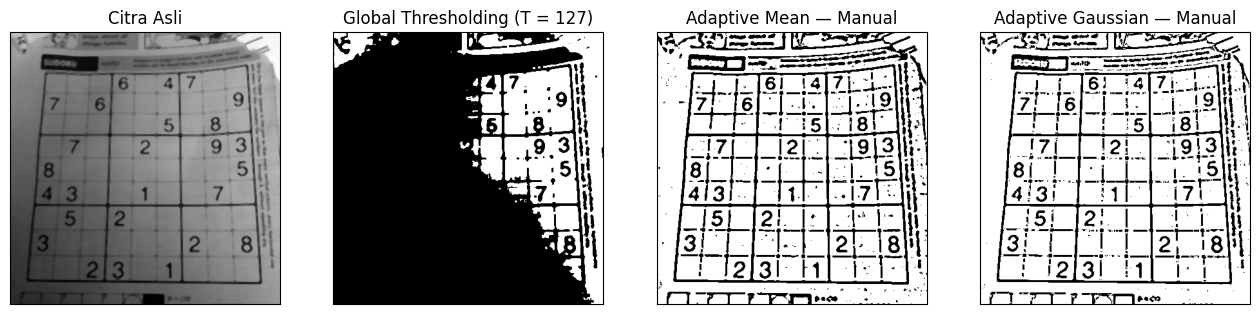

In [5]:
filename = ('/content/drive/MyDrive/Semester5/PCVK/P7_Arifah_04/sudoku-original.jpg')

# --- fungsi bantu (manual) ---
def median_blur_manual(gray, k=5):
    # median blur manual: ambil median dari jendela k x k
    p = k // 2
    pad = np.pad(gray, p, mode='edge')
    h, w = gray.shape
    stack = [pad[dy:dy+h, dx:dx+w] for dy in range(k) for dx in range(k)]
    return np.median(np.stack(stack, axis=0), axis=0).astype(np.uint8)

def mean_local(gray, b):
    # rata-rata lokal b x b memakai integral image
    p = b // 2
    pad = np.pad(gray.astype(np.float64), p, mode='edge')
    ii = np.pad(pad.cumsum(0).cumsum(1), ((1,0),(1,0)), mode='constant')
    h, w = gray.shape
    s = ii[b:b+h, b:b+w] - ii[0:h, b:b+w] - ii[b:b+h, 0:w] + ii[0:h, 0:w]
    return s / (b * b)

def gaussian_kernel_1d(b, sigma):
    x = np.arange(b) - b // 2
    g = np.exp(-(x ** 2) / (2 * sigma ** 2))
    return g / g.sum()

def gaussian_local(gray, b, sigma):
    # rata-rata berbobot Gaussian b x b (konvolusi separabel manual)
    p = b // 2
    g = gaussian_kernel_1d(b, sigma)
    pad = np.pad(gray.astype(np.float64), p, mode='edge')
    h, w = gray.shape
    tmp = sum(g[i] * pad[:, i:i+w] for i in range(b))      # horizontal
    out = sum(g[i] * tmp[i:i+h, :] for i in range(b))      # vertikal
    return out

def global_threshold_manual(gray, T):
    return np.where(gray > T, 255, 0).astype(np.uint8)

def adaptive_threshold_manual(gray, method, b=11, C=2, sigma=2):
    if method == 'mean':
        T = mean_local(gray, b) - C
    else:
        T = gaussian_local(gray, b, sigma) - C
    return np.where(gray > T, 255, 0).astype(np.uint8)

# --- proses ---
citra = cv.imread(filename)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)
gray = median_blur_manual(gray, 5)

thresh = 127

th1 = global_threshold_manual(gray, thresh)
th2 = adaptive_threshold_manual(gray, 'mean', b=11, C=2)
th3 = adaptive_threshold_manual(gray, 'gaussian', b=11, C=2, sigma=2)

titles = ['Citra Asli', 'Global Thresholding (T = 127)',
          'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
citra2 = [gray, th1, th2, th3]

plt.figure(figsize = (16,5))
for i in range(len(citra2)):
    plt.subplot(1,4,i+1),plt.imshow(citra2[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

## Langkah 5A
A. Buat Otsu Thresholding tanpa menggunakan Library. Tampilkan juga nilai threshold
saat anda gunakan Otsu’s, seperti terlihat pada gambar hasil berikut. Gunakan image
lena.jpg untuk dibandingkan dengan hasil dengan penggunaan library.


/tmp/ipykernel_1303/4001965703.py:20: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


114


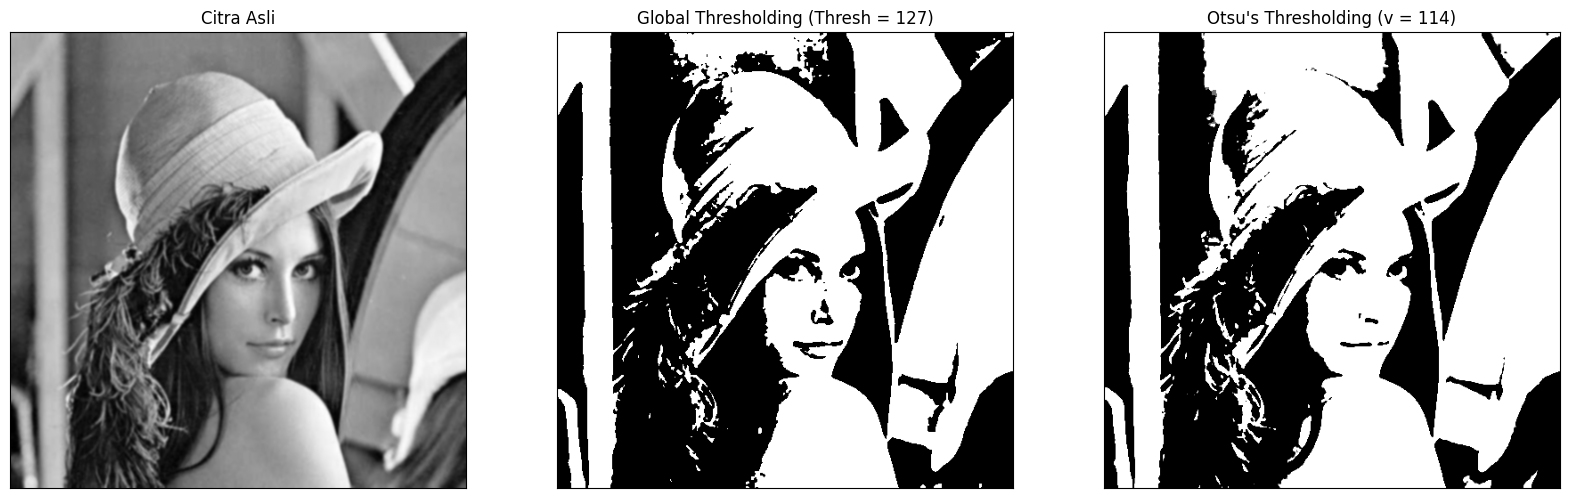

In [50]:
filename = ('/content/drive/MyDrive/Semester5/PCVK/P7_Arifah_04/lena.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

Intensitas min : 0
Intensitas max : 254
Jumlah piksel > 127 : 132769


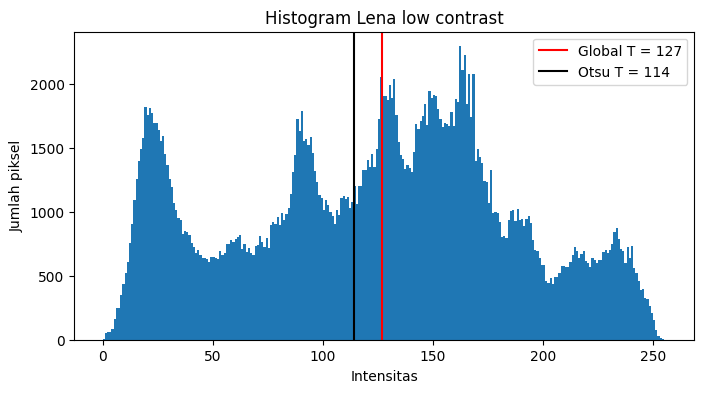

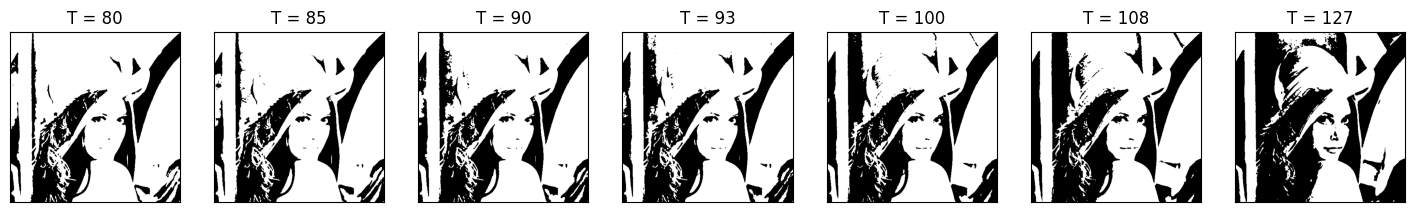

In [53]:
print("Intensitas min :", blur.min())
print("Intensitas max :", blur.max())
print("Jumlah piksel > 127 :", int(np.sum(blur > 127)))

plt.figure(figsize=(8,4))
plt.hist(blur.ravel(), bins=256, range=(0,256))
plt.axvline(127, color='red', label='Global T = 127')
plt.axvline(otsu_thresh, color='black', label=f'Otsu T = {otsu_thresh}')
plt.title('Histogram Lena low contrast')
plt.xlabel('Intensitas'), plt.ylabel('Jumlah piksel')
plt.legend()
plt.show()

Ts = [80, 85, 90, 93, 100, 108, 127]
plt.figure(figsize=(18,3))
for i, T in enumerate(Ts):
    plt.subplot(1, len(Ts), i+1)
    plt.imshow(np.where(blur > T, 255, 0), 'gray')
    plt.title(f'T = {T}')
    plt.xticks([]), plt.yticks([])
plt.show()

## Langkah 5B
B. Kemudian coba dengan image KTP sendiri agar terlihat beda antara hasil otsu’s
dengan global threshold biasa

/tmp/ipykernel_1303/4001965703.py:19: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)


166


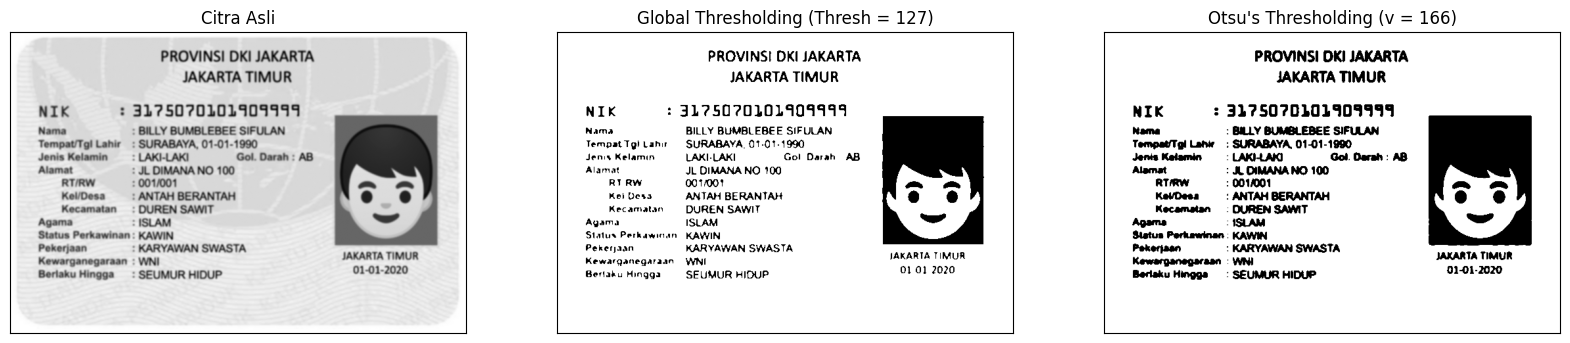

In [8]:
filename = ('/content/drive/MyDrive/Semester5/PCVK/P7_Arifah_04/ktp_fulan.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

hasil Otsu pada KTP bernilai v=166, sama dengan contoh modul. Pada KTP, global T=127 masih berhasil karena kontras citranya tinggi dan histogramnya terpisah jelas, sedangkan pada Lena low contrast hanya Otsu yang berhasil karena T dihitung dari histogram.

**Pertanyaan:** Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam
semuan? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas
(Thresh) supaya gambar Lena ini masih terlihat?

**Jawab:** Hasil Binary Thresholding hitam semua karena citra Lena low contrast hanya memakai rentang intensitas sekitar 80–127 (24 level). Pada histogram, semua batang terkumpul di kiri garis merah T=127, dan tidak ada satu piksel pun yang bernilai lebih dari 127. Aturan Binary adalah piksel > thresh menjadi 255 dan selain itu menjadi 0, sehingga seluruh piksel menjadi 0 (hitam). Agar Lena masih terlihat, T harus berada di dalam rentang intensitas citra, yaitu sekitar 85 sampai 107. Nilai terbaik ada di tengah sebaran piksel, sekitar 90–100, dan Otsu menemukan sekitar 92–93. Jika T ≤ 85 hasilnya putih semua, dan jika T ≥ 108 hasilnya hitam semua.

## Langkah 6A
A. Lakukan Segmentasi Berbasis Region pada citra data.coins() dari skimage.

In [9]:
from skimage import data
img = data.coins()            # grayscale, 303 x 384
print(img.shape, img.dtype)

(303, 384) uint8


Citra ini cocok karena memuat objek yang jelas (koin), latar yang cukup homogen,
dan beberapa koin yang saling bersentuhan. Ketentuan:

• Tentukan 3 seed: satu di dalam koin, satu di latar, dan satu tepat di tepi koin.

• Jalankan dengan T = 5, 20, dan 60.

• Tampilkan hasilnya dalam grid 3×3 (seed × T)
Hasil yang diharapkan (Jumlah piksel belum tentu sama persis dengan contoh):

Seed di dalam koin  (baris, kolom): (36, 43) | intensitas: 159
   T =  5 -> 21 piksel
   T = 20 -> 919 piksel
   T = 60 -> 15253 piksel
Seed di latar  (baris, kolom): (19, 76) | intensitas: 122
   T =  5 -> 3073 piksel
   T = 20 -> 9827 piksel
   T = 60 -> 44440 piksel
Seed di tepi koin  (baris, kolom): (65, 98) | intensitas: 200
   T =  5 -> 14 piksel
   T = 20 -> 490 piksel
   T = 60 -> 1088 piksel


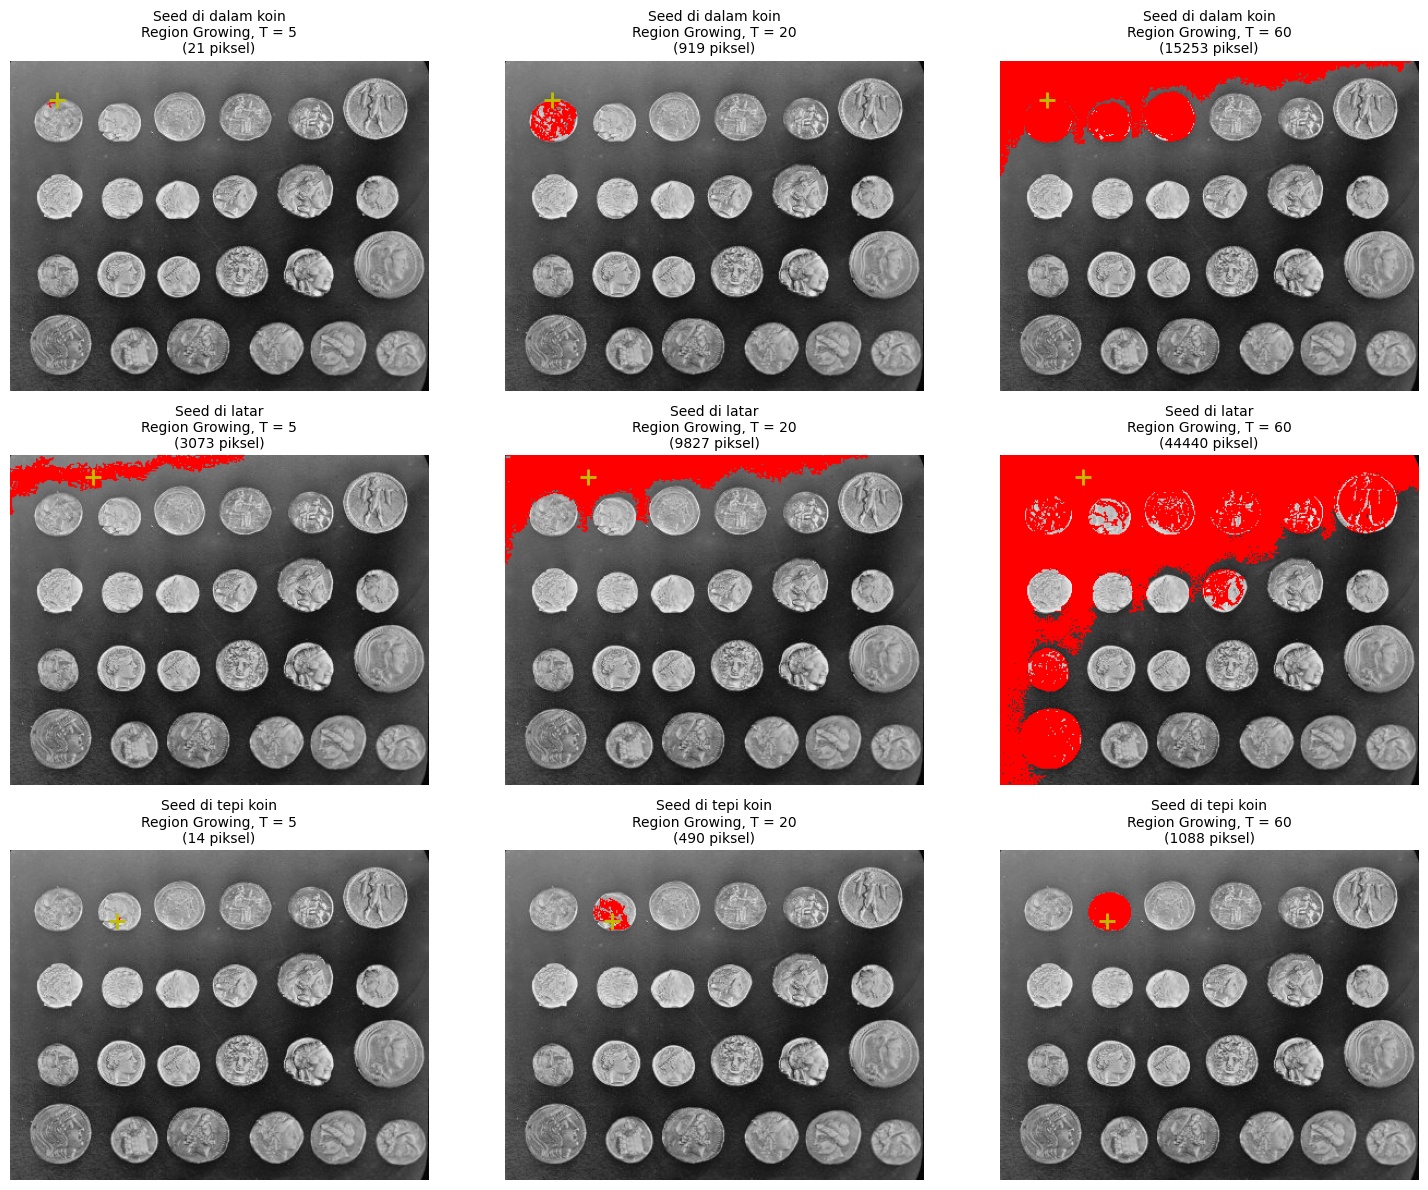

In [27]:
def region_growing(gray, seed, T, connectivity=4):
    # Region growing manual (BFS dengan deque).
    # Piksel tetangga diterima jika |I(q) - I(seed)| <= T
    h, w = gray.shape
    mask = np.zeros((h, w), dtype=bool)
    ref = float(gray[seed])
    if connectivity == 4:
        nbr = [(-1,0),(1,0),(0,-1),(0,1)]
    else:
        nbr = [(-1,-1),(-1,0),(-1,1),(0,-1),(0,1),(1,-1),(1,0),(1,1)]
    queue = deque([seed])
    mask[seed] = True
    while queue:
        r, c = queue.popleft()
        for dr, dc in nbr:
            rr, cc = r + dr, c + dc
            if 0 <= rr < h and 0 <= cc < w and not mask[rr, cc]:
                if abs(float(gray[rr, cc]) - ref) <= T:
                    mask[rr, cc] = True
                    queue.append((rr, cc))
    return mask

gray = data.coins()

seeds = {
    'Seed di dalam koin' : (36, 43),
    'Seed di latar'      : (19, 76),
    'Seed di tepi koin'  : (65, 98),
}
T_list = [5, 20, 60]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for i, (nama_seed, seed) in enumerate(seeds.items()):
    print(f"{nama_seed}  (baris, kolom): {seed} | intensitas: {gray[seed]}")
    for j, T in enumerate(T_list):
        mask = region_growing(gray, seed, T)
        overlay = np.stack([gray, gray, gray], axis=-1).copy()
        overlay[mask] = [255, 0, 0]
        axes[i, j].imshow(overlay)
        axes[i, j].plot(seed[1], seed[0], 'y+', markersize=12, markeredgewidth=2)
        axes[i, j].set_title(f"{nama_seed}\nRegion Growing, T = {T}\n({mask.sum()} piksel)", fontsize=10)
        axes[i, j].axis('off')
        print(f"   T = {T:>2} -> {mask.sum()} piksel")
plt.tight_layout()
plt.show()

Pada seed di dalam koin, T=5 hanya menghasilkan bercak kecil di sekitar seed (21 piksel) karena toleransi terlalu ketat sehingga terjadi over-segmentation. T=20 menghasilkan region yang pas menutupi satu koin (919 piksel). T=60 terlalu longgar sehingga region bocor ke latar dan koin di sebelahnya (15.253 piksel), yaitu under-segmentation. Seed di latar (intensitas 122) pada T=5 hanya menutupi sebagian latar atas, pada T=20 menutupi sebagian latar bagian atas, dan pada T=60 ikut menjalar ke koin-koin yang intensitasnya masih dalam toleransi. Seed di tepi koin bersifat sensitif: pada T=5 hanya 14 piksel karena intensitas tepi (200) sangat berbeda dengan tetangganya, pada T=20 hanya sebagian koin yang terjangkau (490 piksel), dan pada T=60 satu koin penuh (1.088 piksel) tanpa bocor ke latar karena latar jauh lebih gelap dari 140. Dengan demikian hasil region growing sangat bergantung pada posisi seed dan nilai threshold.

## Langkah 6B
Gunakan skimage.segmentation.flood(). Fungsi ini menghasilkan mask region dari
seed dengan menerima piksel yang terhubung dan intensitasnya berada dalam
toleransi terhadap intensitas seed.

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

gray = data.coins()
seed = (121, 63)          # (baris, kolom)

# Segmentasi menggunakan fungsi siap pakai
region = flood(
    gray,
    seed_point=seed,
    tolerance=20,
    connectivity=1        # 4 tetangga untuk citra 2D
)
print("Jumlah piksel region (seed (121, 63), T = 20):", int(region.sum()))

Jumlah piksel region (seed (121, 63), T = 20): 177


Seed (baris, kolom): (36, 43) | intensitas: 159.0
Toleransi  5: 21 piksel
Toleransi 20: 919 piksel
Toleransi 60: 15253 piksel


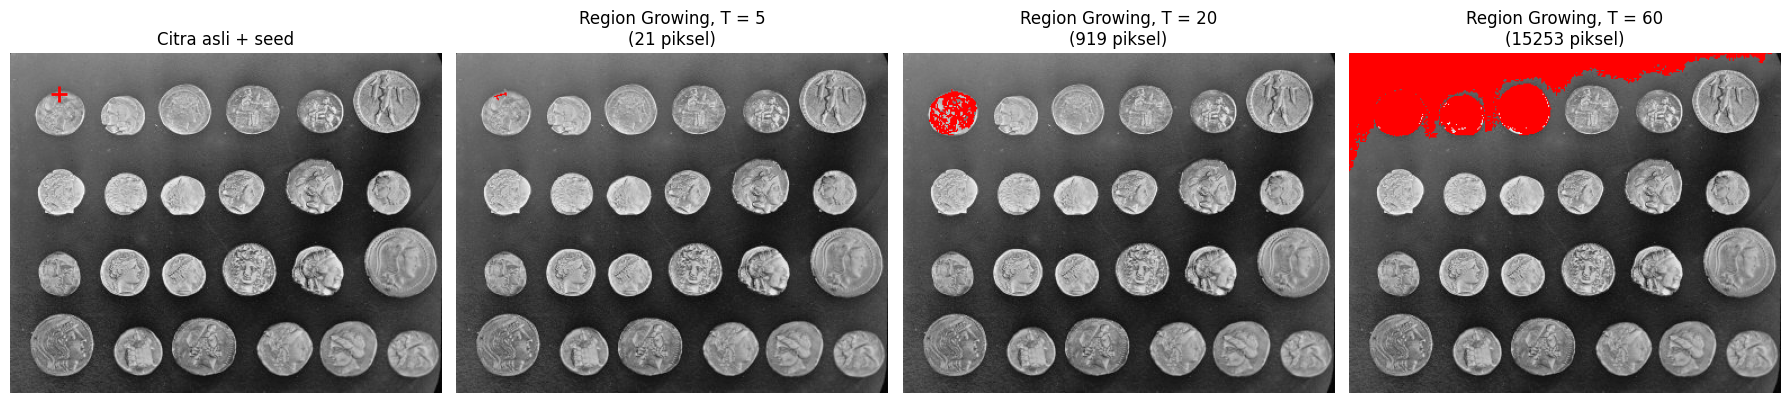

In [29]:
seed = (36, 43)           # seed di dalam koin
print("Seed (baris, kolom):", seed, "| intensitas:", float(gray[seed]))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
axes[0].imshow(gray, cmap='gray')
axes[0].plot(seed[1], seed[0], 'r+', markersize=12, markeredgewidth=2)
axes[0].set_title('Citra asli + seed')
axes[0].axis('off')

for ax, T in zip(axes[1:], [5, 20, 60]):
    region = flood(gray, seed_point=seed, tolerance=T, connectivity=1)
    overlay = np.stack([gray, gray, gray], axis=-1).copy()
    overlay[region] = [255, 0, 0]
    ax.imshow(overlay)
    ax.set_title(f'Region Growing, T = {T}\n({int(region.sum())} piksel)')
    ax.axis('off')
    print(f"Toleransi {T:>2}: {int(region.sum())} piksel")
plt.tight_layout()
plt.show()

## Langkah 7
Lakukan segmentasi warna pada image ktp_fulan.jpg , munculkan hanya warna yang
biru saja. (Petunjuk: anda dapat gunakan K-Means untuk menampilkan hanya warna
tertentu saja).

Rentang mencakup biru muda kebiruan pada latar KTP (dengan warna HSV):
kelompok_biru = np.where( (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40) )

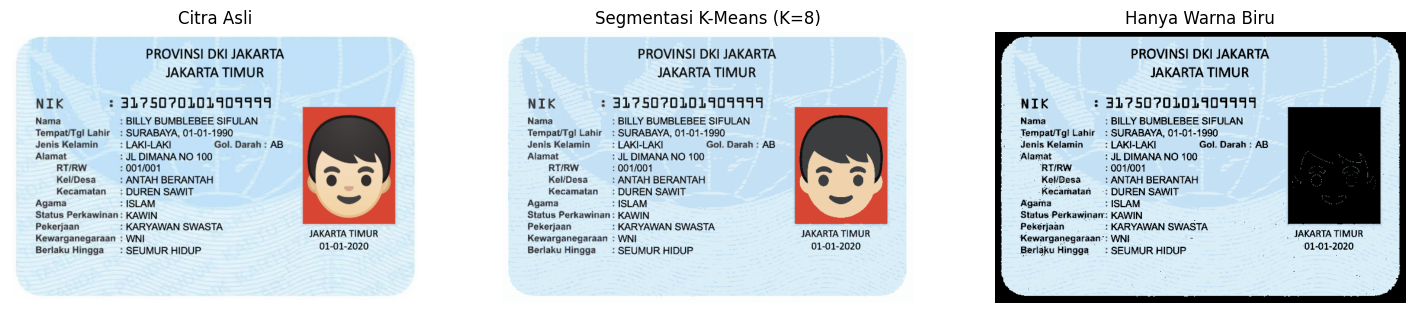

In [13]:
import cv2
from sklearn.cluster import KMeans

# Baca citra dan ubah ke RGB
filename = ('/content/drive/MyDrive/Semester5/PCVK/P7_Arifah_04/ktp_fulan.jpg')

img = cv.imread(filename)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Ubah citra menjadi array 2D (piksel)
Z = img.reshape((-1, 3))
Z = np.float32(Z)

# Tentukan jumlah cluster
k = 8
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(Z)

# Dapatkan label dan pusat cluster
labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)
# Bentuk citra hasil segmentasi
segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)

# Ambil hanya warna biru (rentang HSV)
hsv = cv2.cvtColor(segmented_img, cv2.COLOR_RGB2HSV)
H, S, V = hsv[:,:,0], hsv[:,:,1], hsv[:,:,2]

kelompok_biru = np.where( (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40) )

biru_saja = np.zeros_like(segmented_img)
biru_saja[kelompok_biru] = segmented_img[kelompok_biru]

# Tampilkan hasil
plt.figure(figsize=(18,5))
plt.subplot(1,3,1)
plt.imshow(img)
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(segmented_img)
plt.title('Segmentasi K-Means (K=8)')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(biru_saja)
plt.title('Hanya Warna Biru')
plt.axis('off')
plt.show()

#Tugas Kelompok – OCR pada Citra KTP (Tesseract + pytesseract)

In [14]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


#Langkah 1

In [15]:
import re
import difflib
import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pytesseract
from pytesseract import Output
from IPython.display import display

#Langkah 2

In [34]:
BASE = '/content/drive/MyDrive/Semester5/PCVK/P7_Arifah_04/'

BAHASA   = 'ind'          # bahasa OCR (model tesseract-ocr-ind)
CONFIG   = '--psm 6'      # pengaturan page segmentation mode yang sama
CONF_MIN = 60             # batas confidence untuk kotak hijau
LEBAR    = 1400           # ukuran citra yang sama untuk semua percobaan
BLOCK, C = 75, 20         # parameter Adaptive Thresholding (Gaussian)

# 10 kata acuan (teks sebenarnya) pada masing-masing KTP anggota
anggota = {
    'Anggota 1': {'file': 'KTP_Hapis.jpeg',
                  'acuan': ['PROVINSI','JAWA','TIMUR','KABUPATEN','MALANG','AGAMA','ISLAM','BELUM','KAWIN','SEUMUR']},
    'Anggota 2': {'file': 'KTP_Salma.jpeg',
                  'acuan': ['PROVINSI','JAWA','TIMUR','KABUPATEN','PASURUAN','AGAMA','ISLAM','BELUM','KAWIN','SEUMUR']},
    'Anggota 3': {'file': 'KTP_Jonito.jpeg',
                  'acuan': ['PROVINSI','JAWA','TIMUR','KABUPATEN','BLITAR','AGAMA','ISLAM','BELUM','KAWIN','SEUMUR']},
    'Anggota 4': {'file': 'KTP_Arifah.jpeg',
                  'acuan': ['PROVINSI','JAWA','TIMUR','KABUPATEN','SUMENEP','AGAMA','ISLAM','BELUM','KAWIN','SEUMUR']},
}

#Langkah 3

In [41]:
def siapkan_tiga_citra(path):
    # 1) citra berwarna asli, 2) segmentasi Otsu, 3) segmentasi Adaptive (ukuran sama, grayscale dulu)
    bgr = cv.imread(path)
    h, w = bgr.shape[:2]
    bgr = cv.resize(bgr, (LEBAR, int(h * LEBAR / w)), interpolation=cv.INTER_CUBIC)

    rgb  = cv.cvtColor(bgr, cv.COLOR_BGR2RGB)
    gray = cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)
    blur = cv.GaussianBlur(gray, (5, 5), 0)

    _, otsu = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    adaptive = cv.adaptiveThreshold(blur, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv.THRESH_BINARY, BLOCK, C)
    return {'Berwarna': rgb, 'Otsu': otsu, 'Adaptive': adaptive}


def baca_teks(img):
    # pembacaan teks dengan pytesseract.image_to_string()
    return pytesseract.image_to_string(img, lang=BAHASA, config=CONFIG)


def kotak_hijau(img, conf_min=CONF_MIN):
    # area teks yang dikenali (image_to_data) digambar kotak hijau jika confidence > conf_min
    vis = cv.cvtColor(img, cv.COLOR_GRAY2RGB) if img.ndim == 2 else img.copy()
    data = pytesseract.image_to_data(img, lang=BAHASA, config=CONFIG, output_type=Output.DICT)
    n_kotak = 0
    for i in range(len(data['text'])):
        teks = data['text'][i].strip()
        conf = float(data['conf'][i])
        if teks and conf > conf_min:
            x, y, w, h = data['left'][i], data['top'][i], data['width'][i], data['height'][i]
            cv.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
            n_kotak += 1
    semua = [float(c) for c, t in zip(data['conf'], data['text']) if t.strip() and float(c) >= 0]
    rata_conf = float(np.mean(semua)) if semua else 0.0
    return vis, n_kotak, rata_conf


def cari_kata(acuan, teks_ocr):
    # ambil kata hasil OCR yang paling mirip dengan kata acuan
    token = re.findall(r'[A-Za-z0-9]+', teks_ocr)
    if not token:
        return '(tidak terbaca)'
    def mirip(t):
        return difflib.SequenceMatcher(None, acuan.upper(), t.upper()).ratio()
    terbaik = max(token, key=mirip)
    return terbaik if mirip(terbaik) >= 0.7 else '(tidak terbaca)'


def cocok(acuan, hasil):
    # cocok jika seluruh huruf/angka sama; abaikan huruf besar/kecil dan spasi awal/akhir
    return hasil.strip().upper() == acuan.strip().upper()

#Langkah 4

In [42]:
ringkasan = []   # menampung ringkasan semua anggota

def jalankan(nama_anggota):
    info = anggota[nama_anggota]
    citra = siapkan_tiga_citra(BASE + info['file'])
    judul = {'Berwarna': 'Berwarna', 'Otsu': 'Otsu', 'Adaptive': 'Adaptive'}

    # 1. Tampilkan tiga citra yang dibandingkan
    plt.figure(figsize=(20, 5))
    for i, (k, im) in enumerate(citra.items()):
        plt.subplot(1, 3, i + 1)
        plt.imshow(im, cmap=None if im.ndim == 3 else 'gray')
        plt.title(f'{nama_anggota} – {judul[k]}'), plt.axis('off')
    plt.show()

    # 2 & 3. Baca teks (image_to_string) dan tampilkan area teks (image_to_data, kotak hijau)
    teks, n_kotak, conf = {}, {}, {}
    plt.figure(figsize=(20, 5))
    for i, (k, im) in enumerate(citra.items()):
        teks[k] = baca_teks(im)
        vis, n_kotak[k], conf[k] = kotak_hijau(im)
        plt.subplot(1, 3, i + 1)
        plt.imshow(vis)
        plt.title(f'Area Teks – {judul[k]} (conf > {CONF_MIN}: {n_kotak[k]} kata)'), plt.axis('off')
    plt.show()

    for k in citra:
        print(f'---------- {k.upper()} ----------')
        print(teks[k].strip())
        print()

    # 4. Tabel perbandingan 10 kata
    baris = []
    for no, acuan in enumerate(info['acuan'], start=1):
        baris.append({'No': no, 'Teks sebenarnya': acuan,
                      'OCR citra berwarna': cari_kata(acuan, teks['Berwarna']),
                      'OCR Otsu': cari_kata(acuan, teks['Otsu']),
                      'OCR Adaptive': cari_kata(acuan, teks['Adaptive'])})
    tabel = pd.DataFrame(baris)
    display(tabel.style.hide(axis='index'))

    # 5. Kecocokan dan ringkasan
    nama_kolom = {'Berwarna': 'OCR citra berwarna', 'Otsu': 'OCR Otsu', 'Adaptive': 'OCR Adaptive'}
    nama_baris = {'Berwarna': 'Berwarna asli', 'Otsu': 'Segmentasi Otsu', 'Adaptive': 'Segmentasi Adaptive'}
    isi = []
    for k in citra:
        tepat = sum(cocok(a, h) for a, h in zip(tabel['Teks sebenarnya'], tabel[nama_kolom[k]]))
        persen = tepat / 10 * 100
        isi.append({'Citra masukan OCR': nama_baris[k], 'Item terbaca tepat': tepat,
                    'Kecocokan (%)': persen, 'Rata-rata confidence': round(conf[k], 1)})
        ringkasan.append({'Anggota': nama_anggota, 'Citra masukan OCR': nama_baris[k],
                          'Item terbaca tepat': tepat, 'Kecocokan (%)': persen,
                          'Rata-rata confidence': round(conf[k], 1)})
    display(pd.DataFrame(isi).style.hide(axis='index'))

#Hasil - Anggota 1

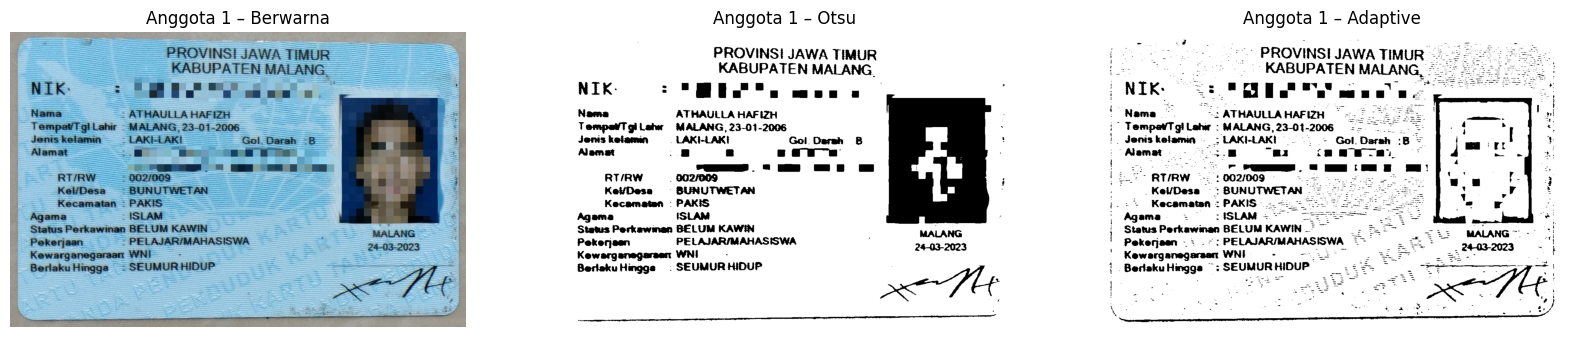

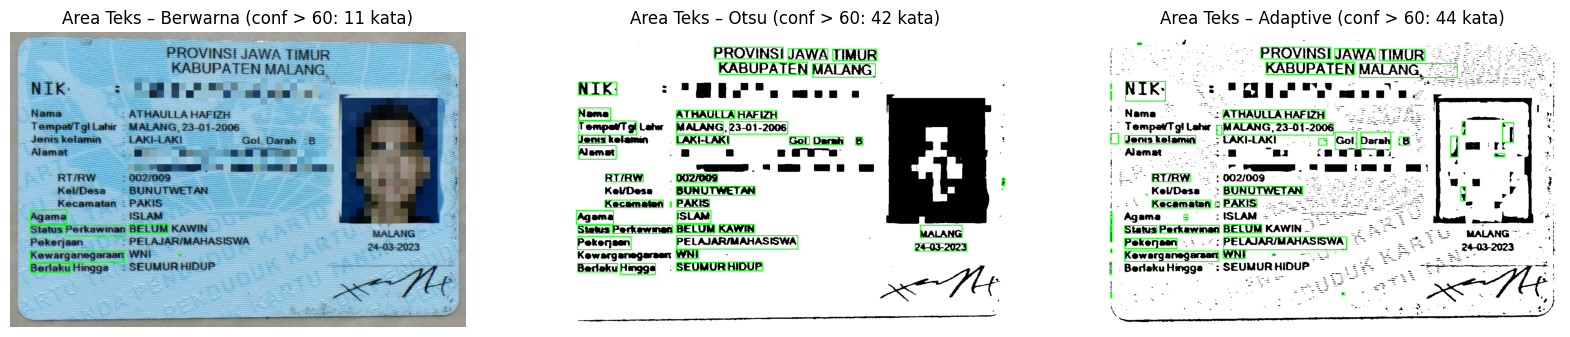

---------- BERWARNA ----------
— ES Ama aa
SONATA
NIK: EN ON akan KN UN
Nama ATHAULLAHAFIZH)”———” | :
 Tempat/TgiLahir MALANG, 23-01-2006 :
Mamat. “ang camai WNAN :
SI UK t
RR OI —— 2 s2 5
— “Kecaaman PAR ————— — 2“
Agama "ASEAN - PP —— 22. | -
Status Perkawinan BELUM KAWIN “2 as
Pekerjaan PELAJAR/IMAHASISWA 3 AA
Kewarganegaraan WNI- - : 25 AA
Berlaku Hingga: SEUMUR HIDUP -— 5 Au

---------- OTSU ----------
PROVINSI JAWA TIMUR
KABUPATEN MALANG
NIK- NN HK nia NN NN N
Nama ATHAULLA HAFIZH '
TempaTgi Lah MALANG, 23-01-2006 '
Jenis kelamin . LAKI-LAKI Gol. Darah B "
Alamat :.. n nu , "
sa “KM Nu - k
RT/RW . 0027009 #
Kel/Desa — BUNUTWETAN ai |
Kecamatan : PAKIS
Agama ISLAM |
Status Perkawinan BELUM KAWIN MALANG
Pekerjaan PELAJAR/MAHASISWA | 24-03-2023
Kewarganegaraan WNI -
Berlaku Hingga : SEUMUR HIDUP Au
0 aj”J”“U“U“U/U/UU

---------- ADAPTIVE ----------
- -4 . : ' INN ANN Pa
Pon Bean PROVINSI JAWA TIMUR 2 Ph
ne Te KABUPATEN MALANG, 5 Ai ui
: Na - ea BER  E
i NIK: 2 Bd Ma umk ni at
| ' Na

No,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
1,PROVINSI,(tidak terbaca),PROVINSI,PROVINSI
2,JAWA,(tidak terbaca),JAWA,JAWA
3,TIMUR,(tidak terbaca),TIMUR,TIMUR
4,KABUPATEN,(tidak terbaca),KABUPATEN,KABUPATEN
5,MALANG,MALANG,MALANG,MALANG
6,AGAMA,Agama,Agama,Agama
7,ISLAM,(tidak terbaca),ISLAM,LISLAM
8,BELUM,BELUM,BELUM,BELUM
9,KAWIN,KAWIN,KAWIN,KAWIN
10,SEUMUR,SEUMUR,SEUMUR,SEUMURHIDUP


Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
Berwarna asli,5,50.000000,27.600000
Segmentasi Otsu,10,100.000000,58.800000
Segmentasi Adaptive,8,80.000000,36.100000


In [43]:
jalankan('Anggota 1')

#Hasil - Anggota 2

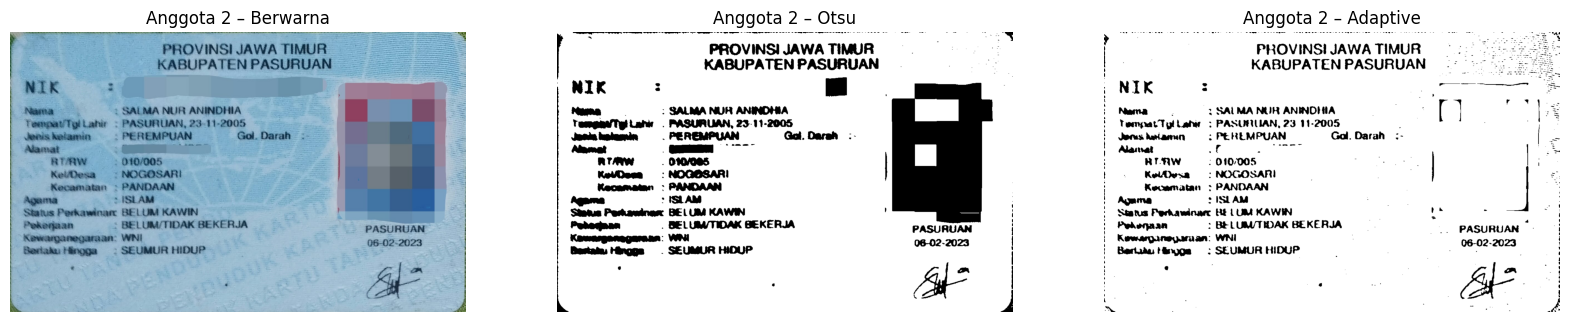

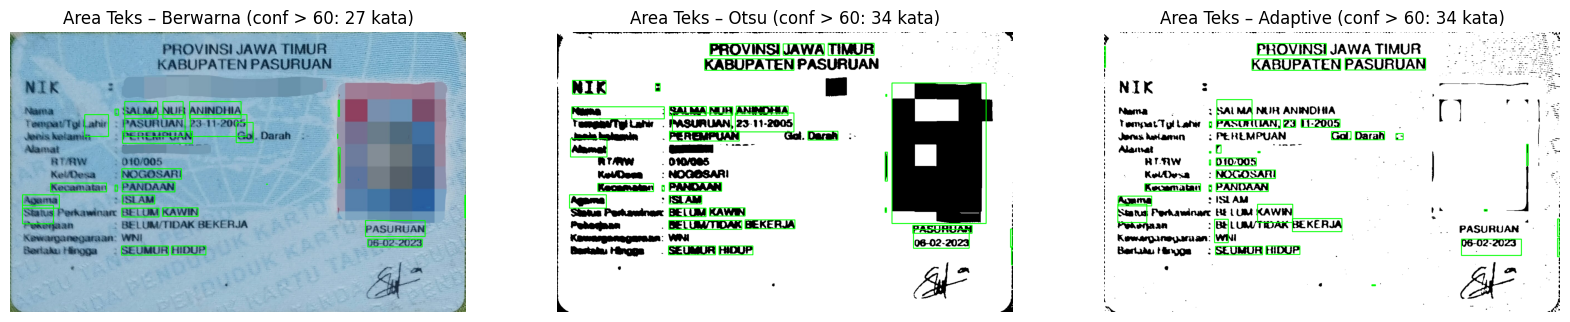

---------- BERWARNA ----------
Pn | KABUPATENPASURUAN ———————————
Nama Bg" : SALMA NUR ANINDHIA 3 2 25 | Ng -
TempavTgi Lahir - PASURUAN, 23-11-2005 5... -
Jenis kelamin —. PEREMPUAN Ga darah — | .
Alamat No UN P3 —
RIMAW 0109/2005 ag S
KelDesa — NOGOSARI An 2 | 2
Kecamatan : PANDAAN z : - .
Agama 2 ISLAM 7 2
Status Perkawinan BELUM KAWIN an |
Kewarganegaraan ra arora PASURUAN
Bariaku Hingga —: SEUMUR HIDUP 06-02-2023
AP

---------- OTSU ----------
Je ae ran
PROVINSI JAWA TIMUR 2
KABUPATEN PASURUAN .
| NIK : || |
Nama: SALMA NUR ANINDHIA d
TempBaTyi Lahk . PASURUAN, 23-11-2005
Janahalamin —. PEREMPUAN Gol. Darah :-
Alamat Z|—.
RTAW ——. ONYOSS |
Kelsea —: NOGBSARI
Kecamatan : PANDAAN
Agama " ISLAM
Status Perkawinan BELUM KAWIN ,
Pehagaan — BELUM/TIDAK BEKERJA PASURUAN :
Kamnsganagaaan : WNI 06-02-2023 |
Bestahu Hingga —. SEUMUR HIDUP |
Ta OP EN

---------- ADAPTIVE ----------
| PROVINSI JAWA TIMUR — tan
Ta KABUPATEN PASURUAN ain
| Nama. 2 SALMA NUH ANINDHIA Kanan GD “Ie
—— Yempat Ty Lah

No,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
1,PROVINSI,(tidak terbaca),PROVINSI,PROVINSI
2,JAWA,(tidak terbaca),JAWA,JAWA
3,TIMUR,(tidak terbaca),TIMUR,TIMUR
4,KABUPATEN,(tidak terbaca),KABUPATEN,KABUPATEN
5,PASURUAN,PASURUAN,PASURUAN,PASURUAN
6,AGAMA,Agama,Agama,(tidak terbaca)
7,ISLAM,ISLAM,ISLAM,ISLAM
8,BELUM,BELUM,BELUM,LUM
9,KAWIN,KAWIN,KAWIN,KAWIN
10,SEUMUR,SEUMUR,SEUMUR,SEUMUR


Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
Berwarna asli,6,60.000000,46.800000
Segmentasi Otsu,10,100.000000,53.100000
Segmentasi Adaptive,8,80.000000,40.900000


In [44]:
jalankan('Anggota 2')

#Hasil - Anggota 3

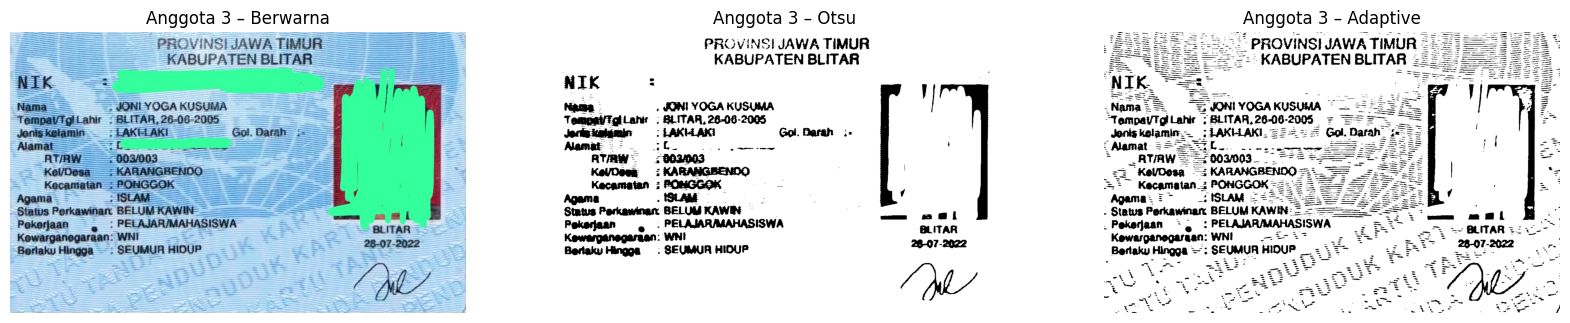

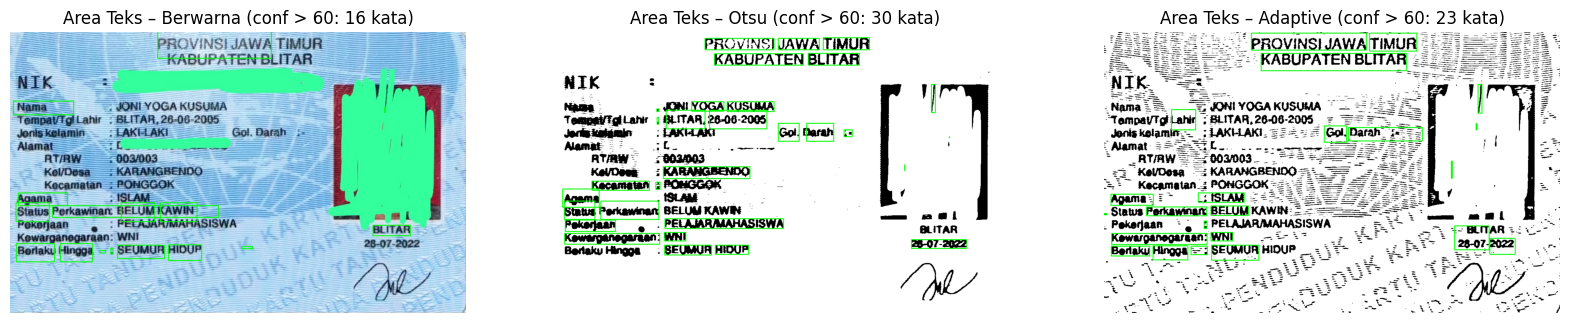

---------- BERWARNA ----------
PROVINSIJAWA TIMUR
Nama —— — JONIYOGAKUSUMA | .
“Tempat/TgiLahir - BLITAR, 26-06-2005 — — — —— — :

Na ee

5 Kecamatan PONGGOK— — — —— :
Agama- ISLAM 53
Status Perkawinan. BELUM KAWIN — ———— ma
Ma en Pe 5 BLITAR
Berlaku Hingga — : SEUMUR HIDUP — 3 - ae ——

---------- OTSU ----------
PROVINSI JAWA TIMUR h
KABUPATEN BLITAR
NIK”:
Nara , SINI YOGA KUSUMA |
TempatIgiLahir : BLITAR, 26-06-2005
Jeriakakarin —: LAKILAKI Gol. Darah :- |
Alamat“. CL... '
RTAW”— 0031003
KelDesa: —: KARANGBENDO |
Kecamatan : PONGGOK -
Agama ISLAM '
Status Perkawinan BELUM KAWIN ”—— a.l
Pekerjaan — , : PELAJARIMAHASISWA TT BLITAR
Kewarganegaraan: WNI
Berlaku Hingga: SEUMUR HIDUP 28-01-2022

---------- ADAPTIVE ----------
(Ea Bali PROVINSIJAWA TIMUR 5 £
(2 isi KABUPATENBLITAR «5
.Nama Lo“ JONI YOGA KUSUMA “5S | 5 IE
#TempayTg Lahir BLITAR, 26-08-2008. - “BSE “5 | -
Jeniskelamin-— :IAKHAKI. 22-05 Gol. Darah 15 2- :
.Namat 2-5 2 ne EP in 25
Fo RTAWE SOOMOO3. SA SEL -
(35 KelDesa “SKARANG

No,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
1,PROVINSI,PROVINSIJAWA,PROVINSI,PROVINSIJAWA
2,JAWA,(tidak terbaca),JAWA,(tidak terbaca)
3,TIMUR,TIMUR,TIMUR,TIMUR
4,KABUPATEN,(tidak terbaca),KABUPATEN,KABUPATENBLITAR
5,BLITAR,BLITAR,BLITAR,BLITAR
6,AGAMA,Agama,Agama,Agama
7,ISLAM,ISLAM,ISLAM,ISLAM
8,BELUM,BELUM,BELUM,BELUM
9,KAWIN,KAWIN,KAWIN,KAWIN
10,SEUMUR,SEUMUR,SEUMUR,SEUMUR


Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
Berwarna asli,7,70.000000,38.500000
Segmentasi Otsu,10,100.000000,56.000000
Segmentasi Adaptive,7,70.000000,31.200000


In [45]:
jalankan('Anggota 3')

#Hasil - Anggota 4

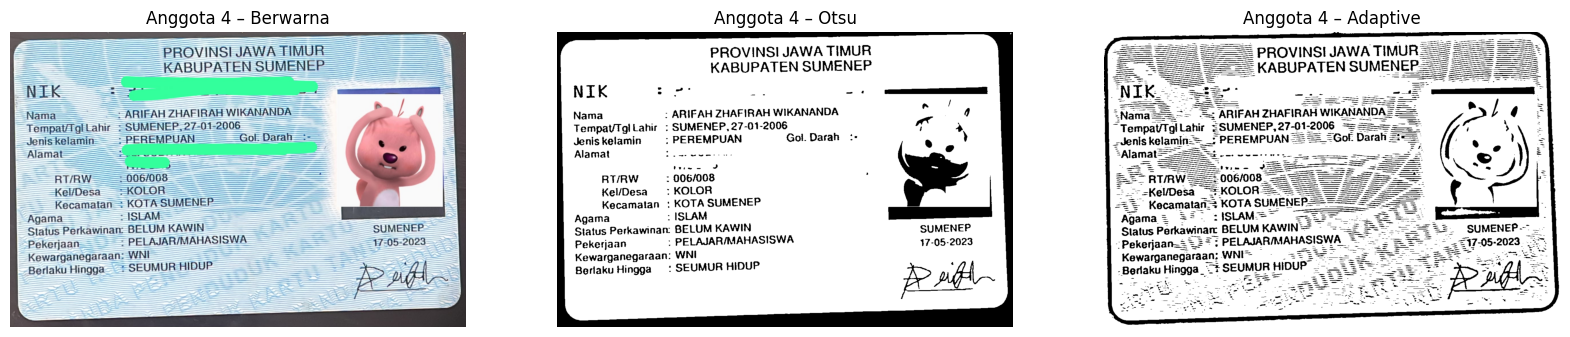

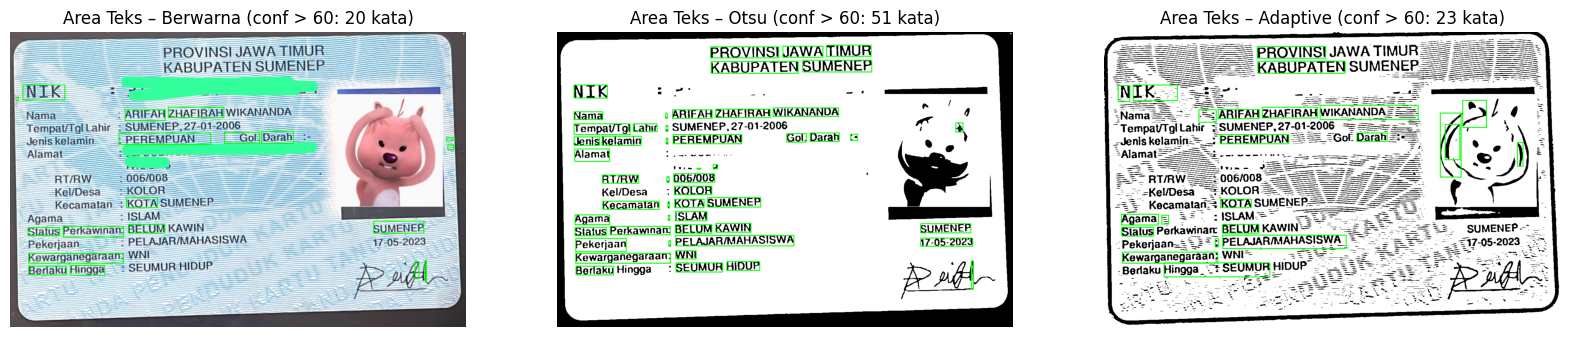

---------- BERWARNA ----------
oo PROVINSIJAWATIMUR
0 KABUPATENSUMENEP
z NIK 2 — . PE Tn Ae “5
Nama — ARIFAH ZHAFIRAH WIKANANDA On / og 3
Tempay/tgiLahir 2#SUMENEP-27-01-2006 —————
Jeniskelamin— — #PEREMPUAN —— “Got Darah —-— 2
Ae 5 oo UU“. 2

FP “PAT
RTRW 20061008 5 -
KelDesa 5KOLOR :
5 Kecamatan KOTA SUMENEP
Agama — ——— ISLAM FP
Status Perkawinan: BELUM KAWIN — TE 5 SUMENEP
Pekerjaan————: PELAJAR/MAHASISWA ———— An
Kewarganegaraan: WNI- AAA AA EA
Berlaku Hingga- —#SEUMUR:-HIDUP-— —— — “5 : 5 1 |

---------- OTSU ----------
PROVINSI JAWA TIMUR
KABUPATEN SUMENEP
NIK 8. -. -.  —...t
Nama : ARIFAH ZHAFIRAH WIKANANDA La ! 1
Tempat/Tgi Lahir : SUMENEP, 27-01-2006 n 3
Jenis kelamin : PEREMPUAN Gol. Darah :- y
Alamat Panama. s (4
trem — 4
RT/RW 1 006/008 :
Keli/Desa : KOLOR
Kecamatan : KOTA SUMENEP
Agama : ISLAM
Status Perkawinan: BELUM KAWIN SUMENEP
Pekerjaan : PELAJAR/MAHASISWA 17-05-2023
Kewarganegaraan: WNI
Berlaku Hingga”: SEUMUR HIDUP : . |

---------- ADAPTIVE ----------
5 PROVINSI JAW

No,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
1,PROVINSI,(tidak terbaca),PROVINSI,PROVINSI
2,JAWA,(tidak terbaca),JAWA,(tidak terbaca)
3,TIMUR,(tidak terbaca),TIMUR,(tidak terbaca)
4,KABUPATEN,KABUPATENSUMENEP,KABUPATEN,KABUPATEN
5,SUMENEP,SUMENEP,SUMENEP,SUMENEP
6,AGAMA,Agama,Agama,Agama
7,ISLAM,ISLAM,ISLAM,ISLAMS
8,BELUM,BELUM,BELUM,BELUM
9,KAWIN,KAWIN,KAWIN,KAWIN
10,SEUMUR,SEUMUR,SEUMUR,SEUMUR


Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
Berwarna asli,6,60.000000,40.300000
Segmentasi Otsu,10,100.000000,72.200000
Segmentasi Adaptive,7,70.000000,30.500000


In [46]:
jalankan('Anggota 4')

#Ringkasan Seluruh Anggota

In [54]:
df = pd.DataFrame(ringkasan)
urutan = ['Berwarna asli', 'Segmentasi Otsu', 'Segmentasi Adaptive']

# Kecocokan (%) tiap anggota
print('Kecocokan (%) per anggota')
display(df.pivot(index='Citra masukan OCR', columns='Anggota', values='Kecocokan (%)').loc[urutan])

# Rata-rata confidence tiap anggota
print('Rata-rata confidence per anggota')
display(df.pivot(index='Citra masukan OCR', columns='Anggota', values='Rata-rata confidence').loc[urutan])

# Rata-rata gabungan seluruh anggota
gabungan = (df.groupby('Citra masukan OCR')[['Item terbaca tepat', 'Kecocokan (%)', 'Rata-rata confidence']]
              .mean().loc[urutan].round(1))
print('Rata-rata gabungan seluruh anggota')
display(gabungan)

Kecocokan (%) per anggota


Anggota,Anggota 1,Anggota 2,Anggota 3,Anggota 4
Citra masukan OCR,,,,
Berwarna asli,50.0,60.0,70.0,60.0
Segmentasi Otsu,100.0,100.0,100.0,100.0
Segmentasi Adaptive,80.0,80.0,70.0,70.0


Rata-rata confidence per anggota


Anggota,Anggota 1,Anggota 2,Anggota 3,Anggota 4
Citra masukan OCR,,,,
Berwarna asli,27.6,46.8,38.5,40.3
Segmentasi Otsu,58.8,53.1,56.0,72.2
Segmentasi Adaptive,36.1,40.9,31.2,30.5


Rata-rata gabungan seluruh anggota


,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
Citra masukan OCR,,,
Berwarna asli,6.0,60.0,38.3
Segmentasi Otsu,10.0,100.0,60.0
Segmentasi Adaptive,7.5,75.0,34.7


#Jawaban Pertanyaan Analisis

1. Citra masukan mana yang paling tepat?
Citra hasil segmentasi Otsu menghasilkan pembacaan paling tepat. Pada tabel ringkasan, kecocokan Otsu mencapai 100% untuk keempat anggota (10 dari 10 kata terbaca tepat), dengan rata-rata gabungan 10 item. Sebagai perbandingan, Adaptive hanya 75% (rata-rata 7,5 item) dan citra berwarna asli 60% (rata-rata 6 item).

2. Contoh kesalahan pembacaan
Kesalahan paling sering terjadi pada kata di bagian header KTP di citra berwarna. Kata “PROVINSI” gagal terbaca tepat pada keempat anggota. Pada KTP Hapis, Salma, dan Arifah, kata “JAWA” dan “TIMUR” tidak terbaca sama sekali, sedangkan pada KTP Jonito “PROVINSI” dan “JAWA” menyatu menjadi “PROVINSIJAWA”. Pada citra Adaptive, huruf bisa tertukar atau terpotong, misalnya “ISLAM” terbaca “LISLAM” (Hapis) dan “ISLAMS” (Arifah), serta “BELUM” terbaca “LUM” (Salma). Ada juga kata yang menyatu dengan kata di sebelahnya, seperti “SEUMURHIDUP” (Hapis) dan “KABUPATENBLITAR” (Jonito).

3. Apakah segmentasi selalu meningkatkan ketepatan OCR?
Tidak selalu. Otsu memang selalu meningkatkan hasil di semua anggota (dari 50–70% menjadi 100%). Adaptive rata-rata lebih baik dari citra berwarna (75% dibanding 60%), tetapi hasilnya tidak konsisten. Pada Jonito kecocokannya sama saja dengan citra berwarna (70%), dan rata-rata confidence-nya justru paling rendah (34,7 dibanding 38,3). Pada Salma, Adaptive memang menaikkan kecocokan dari 60% ke 80%, tetapi kata “Agama” dan “BELUM” yang tadinya terbaca di citra berwarna jadi gagal terbaca. Jadi segmentasi hanya membantu kalau metode dan parameternya cocok dengan citranya. Adaptive di percobaan ini memakai block size 75 dan C = 20.

4. Pengaruh warna dan pola latar belakang
KTP punya latar biru dengan pola garis halus dan tulisan watermark, sehingga pada citra berwarna teks hitam bersaing dengan pola latar. Hal ini terlihat dari kata header yang berada di atas latar berpola, yang paling sering gagal terbaca. Otsu menghitung satu ambang global dari histogram. Dengan begitu latar biru muda ikut menjadi putih bersih, dan hanya teks gelap yang tersisa. Adaptive menghitung ambang per area, sehingga pola latar yang kontrasnya mendekati teks ikut tertangkap sebagai bintik-bintik (terlihat jelas pada citra Adaptive Arifah). Bintik inilah yang membuat confidence Adaptive rendah dan sebagian huruf salah baca.

5. Apakah confidence tertinggi berarti kecocokan tertinggi?
Tidak selalu. Pada Otsu keduanya memang tertinggi (confidence 60,0 dan kecocokan 100%). Tetapi urutan kedua dan ketiga terbalik: confidence citra berwarna (38,3) lebih tinggi dari Adaptive (34,7), padahal kecocokan citra berwarna (60%) lebih rendah dari Adaptive (75%). Hal serupa terlihat per anggota. Pada Salma, confidence citra berwarna 46,8 lebih tinggi dari Adaptive 40,9, tetapi kecocokannya 60% berbanding 80%. Pada Otsu, confidence Arifah 72,2 dan Salma 53,1 sangat berbeda, padahal kecocokan keduanya sama-sama 100%. Confidence adalah keyakinan Tesseract terhadap seluruh teks yang dikenali, sedangkan kecocokan hanya menilai 10 kata acuan, jadi keduanya tidak selalu sejalan.